In [15]:
!pip install finance-datareader

import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [16]:
samsung = fdr.DataReader('005930', '2016')
print(samsung)

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195400  187000  190000  16081656 -0.018088

[2660 rows x 6 columns]


In [17]:
openValues = samsung[['Open']]
print(samsung[['Open']])

              Open
Date              
2016-01-04   25200
2016-01-05   24040
2016-01-06   24160
2016-01-07   23320
2016-01-08   23260
...            ...
2026-11-03  220500
2026-11-04  226500
2026-11-05  213000
2026-11-06  180000
2026-11-09  187200

[2660 rows x 1 columns]


In [18]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(openValues)
print(scaled)

[[0.06765101]
 [0.06453691]
 [0.06485906]
 ...
 [0.57181208]
 [0.48322148]
 [0.50255034]]


In [19]:
TEST_SIZE = 200
train_data =scaled[:-TEST_SIZE]
test_data = scaled[-TEST_SIZE:]

In [20]:
def make_sample(data, window):
  train = []
  target = []
  for i in range(len(data)-window):
    train.append(data[i:i+window])
    target.append(data[i+window])
  return np.array(train), np.array(target)

WINDOW = 30

X_train, y_train = make_sample(train_data, WINDOW)
print(X_train.shape)

(2430, 30, 1)


In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, Input

model = Sequential()
model.add(SimpleRNN(16,
                    activation='tanh',
                    return_sequences=False))
model.add(Dense(1))

In [22]:
model.compile(optimizer ='adam',
              loss='mean_squared_error')
model.fit(X_train, y_train, epochs = 100, batch_size = 16)

Epoch 1/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0484
Epoch 2/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0018
Epoch 3/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0015
Epoch 4/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0014
Epoch 5/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0012
Epoch 6/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0011
Epoch 7/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.4497e-04
Epoch 8/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.8043e-04
Epoch 9/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.0612e-04
Epoch 10/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 5.8456e-04
Epoch 11/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.1986e-04
Epoch 12/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.8454e-04
Epoch 13/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 4.3223e-04
Epoch 14/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 3.9093e-04
Epoch 15/10

In [23]:
X_test, y_test = make_sample(test_data, WINDOW)
pred = model.predict(X_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step


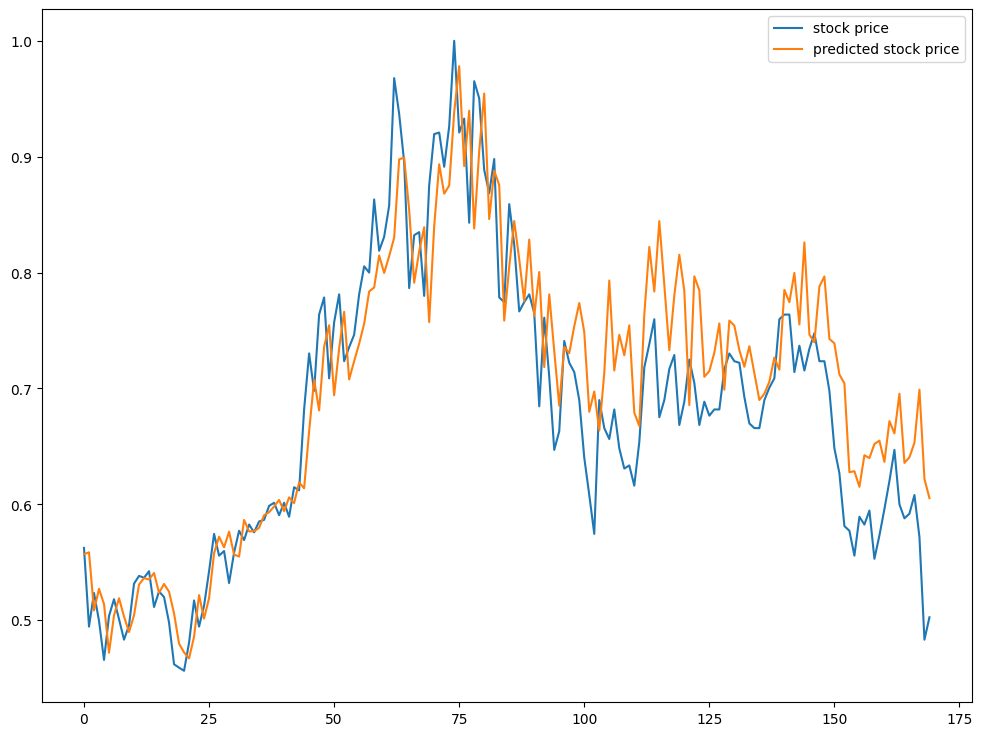

In [24]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 9))
plt.plot(y_test, label ='stock price')
plt.plot(pred, label='predicted stock price')
plt.legend()
plt.show()

In [25]:
from sklearn.metrics import mean_squared_error
print('RNN', WINDOW, mean_squared_error(y_test, pred))

RNN 30 0.0034930055619572095
